# How does language organize emotions?

**Author :** Nathan Tessot

**Date :** May 2026

# 1. Introduction

When we think about emotions, we naturally group some of them together : "joy" and "happiness" feel related, while "joy" and "anger" feel like opposites.

Researchers have shown that words (and especially emotions) can be described along three dimensions : Valence (positive/negative), Arousal (calm/exciting), and Dominance (feeling in control/feeling overwhelmed). This is the VAD model, and Warriner et al. (2013) provide these scores for nearly 14 000 English words.

On the other hand, computational linguists have developed tools like Word2Vec (Mikolov et al., 2013) that learn to represent words as numerical vectors (embeddings) based on how they are used. Words that appear in similar contexts end up with similar vectors, without any human labeling.

This leads to an interesting question : do emotion words that are used in similar linguistic contexts also share similar psychological characteristics ? This is interesting because if yes, it would mean that the way we use words in everyday language already reflects how we experience emotions.

My goal here is to see, modestly, how language really organizes emotions.

My prediction is that Valence (the positive/negative dimension) is the main factor that drives how emotions are organized in language, while Arousal and Dominance play a smaller or insignificant role.


**⚠️ Note :** The first run of this notebook may take a few minutes, as it needs to download the Word2Vec model (~1.7 GB). After that, the model is stored locally and next runs will be much faster.

**⚠️ Note :** The code of the 3D visualization part was generated with the help of the artificial intelligence.

# 2. Library import

In [20]:
# data manipulation
import pandas as pd
import numpy as np
from itertools import combinations

# visualization
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.graph_objects as go

# Embeddings
import gensim.downloader as api

# statistics
from scipy.stats import ttest_ind
import statsmodels.api as sm


# 3. Data import

For this project I use two types of data :

- **VAD ratings** from the Warriner et al. (2013) dataset, which gives Valence, Arousal and Dominance scores for almost 14 000 WORDS of English on a scale from 1 to 9 (can be found here : https://github.com/JULIELab/XANEW). Of those 14 000 words, I only keep emotions (in a broad sense).
  - Valence : how negative or positive the word feels
  - Arousal : how calm or exciting the word feels
  - Dominance : how controlled or in-control the word feels

- **Word embeddings** from the Word2Vec model trained on Google News (Mikolov et al., 2013), which lets us compute how semantically similar two words are based on the contexts they appear in. The vectors are 300-dimensional, which provides a richer representation than smaller models.

## a. Loading the VAD dataset

In [21]:
# loading the csv file (Warriner et al. 2013)
df = pd.read_csv("Ratings_Warriner_et_al.csv")

# keeping only important columns
df_vad = df[["Word", "V.Mean.Sum", "A.Mean.Sum", "D.Mean.Sum"]].dropna()

# renaming columns so its easier to work with
df_vad.columns = ["Word", "Valence", "Arousal", "Dominance"]

# putting everything in lowercase and removing extra spaces
df_vad["Word"] = df_vad["Word"].astype(str).str.lower().str.strip()

# setting Word as the index for easier lookups later
df_vad.set_index("Word", inplace=True)

df_vad

,Valence,Arousal,Dominance
Word,,,
aardvark,6.26,2.41,4.27
abalone,5.30,2.65,4.95
abandon,2.84,3.73,3.32
abandonment,2.63,4.95,2.64
abbey,5.85,2.20,5.00
...,...,...,...
zone,4.75,3.78,5.23
zoning,4.65,3.77,4.47
zoo,7.00,5.63,6.33


## b. Selecting the emotion words

I chose a list of common emotion words that covers a wide range of human feelings, from basic emotions (anger, fear, joy) to more complex ones (compassion, embarrassment, gratitude). The idea is to have enough variety to see if the patterns hold across different types of emotions.

In [22]:
# my list of emotion words to study
emotion_words = [
    "anger", "anxiety", "bad", "disgust", "envy", "fear", "good", "grief",
    "guilt", "happiness", "hate", "hope", "jealousy", "joy", "love", "pain",
    "pity", "pride", "regret", "sadness", "shame", "surprise", "want", "worry",
    "awe", "compassion", "contempt", "contentment", "courage", "curiosity",
    "depression", "desire", "despair", "disappointment", "embarrassment",
    "enthusiasm", "excitement", "frustration", "gratitude", "greed",
    "loneliness", "lust", "nervousness", "optimism", "panic", "passion",
    "relief", "remorse", "satisfaction", "stress", "sympathy", "tension",
    "terror"
]

# only keeping emotions that are in the VAD dataset
valid_emotions = [w for w in emotion_words if w in df_vad.index]

print(valid_emotions)

['anger', 'anxiety', 'bad', 'disgust', 'envy', 'fear', 'good', 'grief', 'guilt', 'happiness', 'hate', 'hope', 'jealousy', 'joy', 'love', 'pain', 'pity', 'pride', 'regret', 'sadness', 'shame', 'surprise', 'want', 'worry', 'awe', 'compassion', 'contempt', 'contentment', 'courage', 'curiosity', 'depression', 'desire', 'despair', 'disappointment', 'embarrassment', 'enthusiasm', 'excitement', 'frustration', 'gratitude', 'greed', 'loneliness', 'lust', 'nervousness', 'optimism', 'panic', 'passion', 'relief', 'remorse', 'satisfaction', 'stress', 'sympathy', 'tension', 'terror']


## c. Distribution of the VAD scores for our emotions

Before doing any analysis, let's look at how our emotion words are distributed across each dimension.

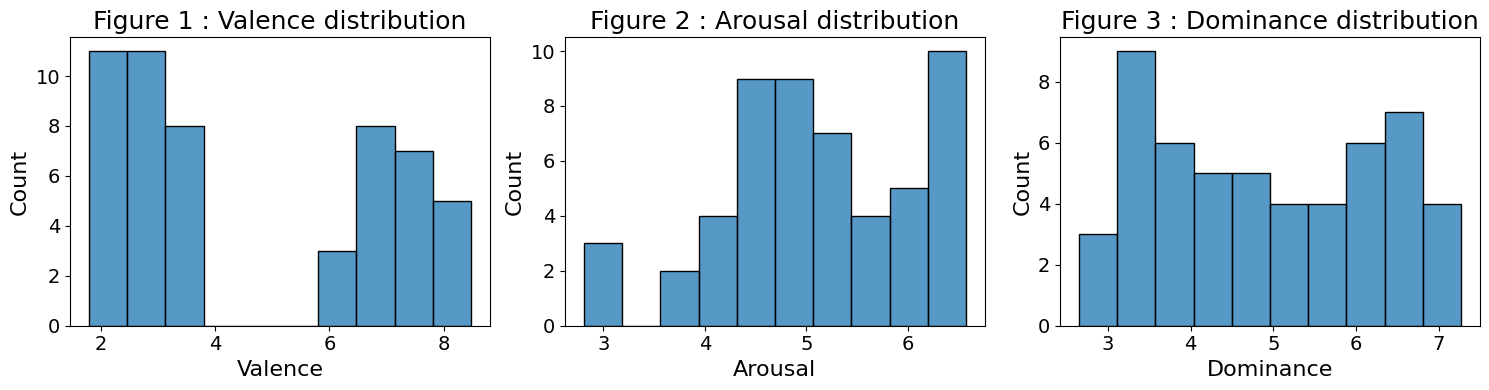

In [23]:
# extracting the VAD data for our emotions
df_emotions = df_vad[df_vad.index.isin(valid_emotions)].reset_index()

# plotting histograms for each VAD dimension
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1. Valence
sns.histplot(data=df_emotions, x="Valence", ax=axes[0], bins=10)
axes[0].set_title("Figure 1 : Valence distribution", fontsize=18)
axes[0].set_xlabel("Valence", fontsize=16)
axes[0].set_ylabel("Count", fontsize=16)
axes[0].tick_params(labelsize=14)

# 2. Arousal
sns.histplot(data=df_emotions, x="Arousal", ax=axes[1], bins=10)
axes[1].set_title("Figure 2 : Arousal distribution", fontsize=18)
axes[1].set_xlabel("Arousal", fontsize=16)
axes[1].set_ylabel("Count", fontsize=16)
axes[1].tick_params(labelsize=14)

# 3. Dominance
sns.histplot(data=df_emotions, x="Dominance", ax=axes[2], bins=10)
axes[2].set_title("Figure 3 : Dominance distribution", fontsize=18)
axes[2].set_xlabel("Dominance", fontsize=16)
axes[2].set_ylabel("Count", fontsize=16)
axes[2].tick_params(labelsize=14)

plt.tight_layout()
plt.show()

# 4. Analysis

## a. Computing semantic similarity

I use Word2Vec embeddings (trained on Google News) to compute the cosine similarity between every pair of emotions. If two words have a similarity above a certain threshold, I consider them as "semantically linked". I chose 0.50 as the threshold because Word2Vec similarities for related words typically fall in the 0.3-0.7 range, and 0.50 captures meaningful connections without being too restrictive.

In [24]:
# loading the pre-trained Word2Vec model
# this may take a moment on first run as it downloads the model (1.7 GB)
w2v_model = api.load("word2vec-google-news-300")

# computing similarity for all pairs
edges_data = []
THRESHOLD = 0.50  # threshold for considering a semantic link

for w1, w2 in combinations(valid_emotions, 2):
    # check that both words are in the vocabulary
    if w1 in w2v_model and w2 in w2v_model:
        sim = w2v_model.similarity(w1, w2)
        if sim >= THRESHOLD:
            edges_data.append({"source": w1, "target": w2, "similarity": round(float(sim), 4)})

# putting it in a dataframe
df_edges = pd.DataFrame(edges_data)

df_edges

,source,target,similarity
0,anger,anxiety,0.5721
1,anger,disgust,0.6864
2,anger,grief,0.5619
3,anger,jealousy,0.5275
4,anger,despair,0.5188
...,...,...,...
84,greed,lust,0.5463
85,nervousness,optimism,0.5803
86,nervousness,panic,0.5695
87,nervousness,tension,0.5528


## b. Visualizing the links

Let's see what the distribution of similarities looks like for the linked pairs.

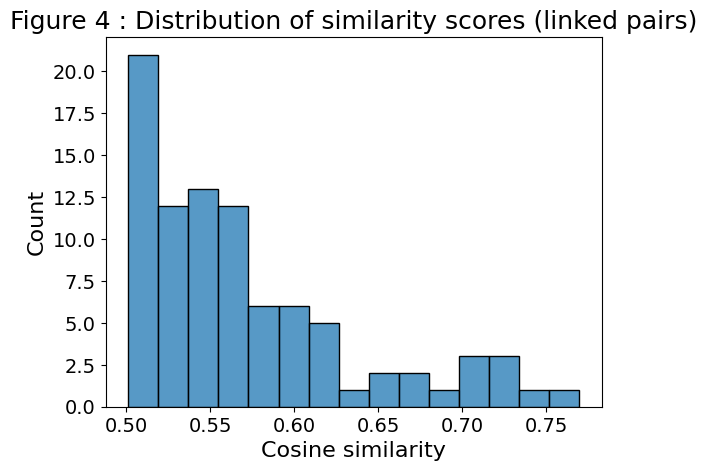

In [25]:
# distribution of similarity values
sns.histplot(data=df_edges, x="similarity", bins=15)
plt.title("Figure 4 : Distribution of similarity scores (linked pairs)", fontsize=18)
plt.xlabel("Cosine similarity", fontsize=16)
plt.ylabel("Count", fontsize=16)
plt.tick_params(labelsize=14)
plt.show()

## c. 3D visualization of emotions in VAD space

To get a better intuition of how emotions are organized, let's plot them in the 3D VAD space. Each dot is an emotion, and the lines connect pairs that are semantically linked (similarity > 0.50).

In [26]:
# ------ CODE GENERATED WITH GEMINI 3.1 Pro ------

def plot_emotion_topography(df_edges, df_vad, min_similarity):
    """
    Parameters:
        df_edges (pd.DataFrame): DataFrame containing source, target, similarity columns.
        df_vad (pd.DataFrame): DataFrame indexed by word with Valence, Arousal, Dominance columns.
        min_similarity (float): Minimum cosine similarity to display an edge.
    """

    # Step 1: Filter edges to only keep those above the similarity threshold
    filtered_edges = df_edges[df_edges["similarity"] >= min_similarity]

    # Step 2: Extract the unique set of emotion nodes involved in the filtered edges
    nodes = set(filtered_edges["source"]).union(set(filtered_edges["target"]))
    valid_nodes = [n for n in nodes if n in df_vad.index]
    node_data = df_vad.loc[valid_nodes].reset_index()

    # Step 3: Create the scatter trace for emotion nodes
    trace_nodes = go.Scatter3d(
        x=node_data["Valence"],
        y=node_data["Arousal"],
        z=node_data["Dominance"],
        mode="markers+text",
        text=node_data["Word"],
        textposition="top center",
        marker=dict(
            size=8,
            color=node_data["Valence"],
            colorscale="Viridis",
            opacity=0.9,
            line=dict(width=1, color="DarkSlateGrey")
        ),
        name="Emotions"
    )

    # Step 4: Create the line trace for semantic links between emotion pairs
    edge_x, edge_y, edge_z = [], [], []
    for _, row in filtered_edges.iterrows():
        n1, n2 = row["source"], row["target"]
        if n1 in df_vad.index and n2 in df_vad.index:
            x0, y0, z0 = df_vad.loc[n1]
            x1, y1, z1 = df_vad.loc[n2]
            edge_x.extend([x0, x1, None])
            edge_y.extend([y0, y1, None])
            edge_z.extend([z0, z1, None])

    trace_edges = go.Scatter3d(
        x=edge_x, y=edge_y, z=edge_z,
        mode="lines",
        line=dict(color="rgba(150, 150, 150, 0.4)", width=3),
        name=f"Semantic link (>{min_similarity})"
    )

    # Step 5: Configure the 3D layout with axis labels and styling
    layout = go.Layout(
        title=f"Figure 5 : 3D Emotion Topography (similarity > {min_similarity})",
        scene=dict(
            xaxis_title="Valence",
            yaxis_title="Arousal",
            zaxis_title="Dominance",
            bgcolor="rgb(240, 240, 240)"
        ),
        margin=dict(l=0, r=0, b=0, t=50),
        legend=dict(x=0.8, y=0.9),
        height=700
    )

    # Step 6: Assemble and render the final figure
    fig = go.Figure(data=[trace_edges, trace_nodes], layout=layout)
    fig.show()

# Displaying the 3D visualization with the previously defined threshold
plot_emotion_topography(df_edges, df_vad, THRESHOLD)


## d. Computing distances in VAD space

Now I compute the euclidean distance in the VAD space for every pair of emotions. The key question is : are the pairs that are semantically linked also closer in the VAD space ?

In [27]:
# getting all unique emotion nodes from our edges
source_nodes = set(df_edges["source"])
target_nodes = set(df_edges["target"])
all_nodes = source_nodes.union(target_nodes)

# only keeping nodes that are in the VAD dataset
valid_nodes = []
for n in all_nodes:
    if n in df_vad.index:
        valid_nodes.append(n)

# computing distances for all pairs
pairs_data = []

for w1, w2 in combinations(valid_nodes, 2):
    c1 = df_vad.loc[w1]
    c2 = df_vad.loc[w2]

    # difference on each VAD axis
    dV = abs(c1["Valence"] - c2["Valence"])
    dA = abs(c1["Arousal"] - c2["Arousal"])
    dD = abs(c1["Dominance"] - c2["Dominance"])

    # euclidean distance in 3D VAD space
    dist = np.sqrt(dV**2 + dA**2 + dD**2)

    # checking if this pair has a semantic link (in either direction)
    match_1 = (df_edges["source"] == w1) & (df_edges["target"] == w2)
    match_2 = (df_edges["source"] == w2) & (df_edges["target"] == w1)
    is_linked = (match_1 | match_2).any()

    # storing the result
    row = {}
    row["pair"] = w1 + "-" + w2
    row["distance"] = dist
    row["delta_V"] = dV
    row["delta_A"] = dA
    row["delta_D"] = dD
    row["linked"] = 1 if is_linked else 0
    pairs_data.append(row)

df_pairs = pd.DataFrame(pairs_data)

df_pairs

,pair,distance,delta_V,delta_A,delta_D,linked
0,pain-lust,4.421018,4.26,0.17,1.17,0
1,pain-contentment,5.814241,4.62,1.67,3.11,0
2,pain-greed,1.955428,0.48,1.82,0.53,0
3,pain-optimism,6.375845,5.21,1.32,3.43,0
4,pain-sympathy,6.079959,4.57,3.19,2.43,0
...,...,...,...,...,...,...
1123,regret-satisfaction,4.222251,3.77,1.72,0.81,0
1124,regret-good,4.713428,4.48,1.24,0.78,0
1125,nervousness-satisfaction,4.955744,4.08,1.27,2.51,0
1126,nervousness-good,5.451477,4.79,0.79,2.48,0


## e. Comparing distances : boxplot

Let's visually compare the distances between linked and unlinked pairs.

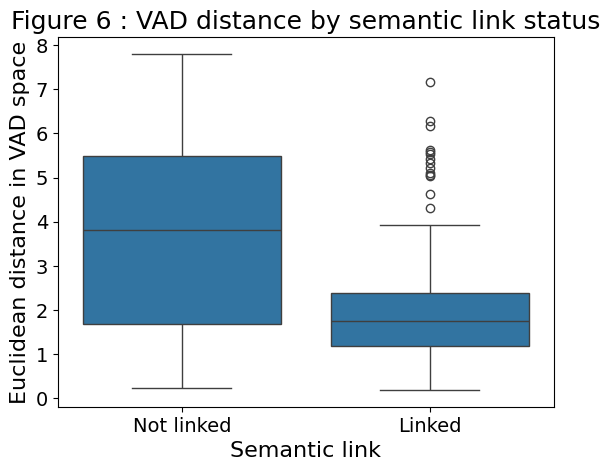

In [28]:
# boxplot comparing distances
sns.boxplot(data=df_pairs, x="linked", y="distance")
plt.xticks([0, 1], ["Not linked", "Linked"])
plt.xlabel("Semantic link", fontsize=16)
plt.ylabel("Euclidean distance in VAD space", fontsize=16)
plt.title("Figure 6 : VAD distance by semantic link status", fontsize=18)
plt.tick_params(labelsize=14)
plt.show()

# 5. Statistical results

## a. Welch's T-test

To test if the difference in distance is statistically significant, I use a Welch's T-test.

In [29]:
# separating the two groups
dist_linked = df_pairs[df_pairs["linked"] == 1]["distance"]
dist_not_linked = df_pairs[df_pairs["linked"] == 0]["distance"]

# welch t-test
t_stat, p_val = ttest_ind(dist_linked, dist_not_linked, equal_var=False)

print(f"Mean distance (linked pairs)     : {dist_linked.mean():.2f}")
print(f"Mean distance (not linked pairs) : {dist_not_linked.mean():.2f}")
print(f"T-test result : t = {t_stat:.2f}, p-value = {p_val:.3e}")

Mean distance (linked pairs)     : 2.26
Mean distance (not linked pairs) : 3.63
T-test result : t = -7.58, p-value = 9.858e-12


## b. Logistic regression

I make a logistic regression to see which of the three VAD dimensions (Valence, Arousal, Dominance) best predicts whether two emotions are semantically linked. The dependent variable is the "linked" status (binary 0 or 1) and the independent variables are the absolute differences on each axis.

In [30]:
# logistic regression
X = df_pairs[["delta_V", "delta_A", "delta_D"]]
y = df_pairs["linked"]

X_with_const = sm.add_constant(X)

logit_model = sm.Logit(y, X_with_const)
result = logit_model.fit(disp=0)
print(result.summary())

                           Logit Regression Results                           
Dep. Variable:                 linked   No. Observations:                 1128
Model:                          Logit   Df Residuals:                     1124
Method:                           MLE   Df Model:                            3
Date:                Fri, 29 May 2026   Pseudo R-squ.:                 0.06891
Time:                        16:51:27   Log-Likelihood:                -289.95
converged:                       True   LL-Null:                       -311.41
Covariance Type:            nonrobust   LLR p-value:                 2.561e-09
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.4575      0.230     -6.335      0.000      -1.908      -1.007
delta_V       -0.2209      0.091     -2.417      0.016      -0.400      -0.042
delta_A       -0.0523      0.146     -0.359      0.7

# 6. Conclusion

### Are semantically linked emotions closer in VAD space?

The **Welch's T-test** shows a highly significant difference (p < 0.001) : semantically linked pairs have a mean VAD distance of 2.26, compared to 3.63 for unlinked pairs.

In other words, emotion pairs that are used in similar contexts in language are closer in psychological space than pairs that are not (that's a reassuring result).


### Which VAD dimension matters most?

The **logistic regression** reveals which dimensions drive this proximity. My initial prediction was that Valence alone would organize emotional vocabulary. The results partially contradict this :

- **Valence** (p = 0.016) and **Dominance** (p = 0.021) are both significant predictors of semantic proximity. Emotions that are close on the positive/negative axis AND on the control/submission axis are more likely to be used in similar contexts.
- **Arousal** (p = 0.720) has no significant effect : whether an emotion is calm or exciting does not influence how it is organized in our use of language.

Interestingly, the Dominance coefficient (−0.40) is larger than the Valence one (−0.22), suggesting that the feeling of being in control or overwhelmed plays an even stronger role than we might expect in shaping emotional vocabulary !

This means that our emotional vocabulary is not just a simple positive/negative split. Language also captures how much control we feel over our emotions (and this is reflected in the way we use words !).

### Limitations

However, there are some limitations to keep in mind :
- This study only covers English. Emotions might be organized differently in other languages.
- The selection of 54 emotion words was made manually, and a different set of words could lead to different results.
- The VAD ratings come from a single study with mainly American speakers, so these scores might not generalize to other populations.

# 7. References

Warriner, A. B., Kuperman, V., & Brysbaert, M. (2013). *Norms of valence, arousal, and dominance for 13,915 English lemmas*. Behavior Research Methods, 45(4), 1191-1207. https://doi.org/10.3758/s13428-012-0314-x

Mikolov, T., Chen, K., Corrado, G., & Dean, J. (2013). *Efficient Estimation of Word Representations in Vector Space*. arXiv preprint arXiv:1301.3781. https://arxiv.org/abs/1301.3781